# Granger Causality Analysis
We are conducting Granger Causality Analysis agasint 1,2,3,7,14,21,28, for both short term and long term indicators.
Here, short term indicators are daily indicators and long term indicators are monthly indicators.

We choose the smallest p-value amongst the values computed from the F-test as the result of the Granger Causality Analysis.

The 'range' of Causality Analysis is the length of lag for which p<0.05.
https://sci-hub.se/https://doi.org/10.2307/1391720

We detrend all data before begining.

In [2]:
import pandas as pd
import matplotlib
import numpy as np
import math
lags = [1,2,3,7,8,9,10]

from scipy import signal
from scipy.interpolate import interp1d

In [3]:
def detrend(series, name):
    #This function detrends the data
    series[name] = np.log(series[name])
    series = series.diff()[1:]
    return series

In [4]:
def dropBad(merged):
    return merged.replace([np.inf, -np.inf], np.nan).dropna()

<Axes: xlabel='Date'>

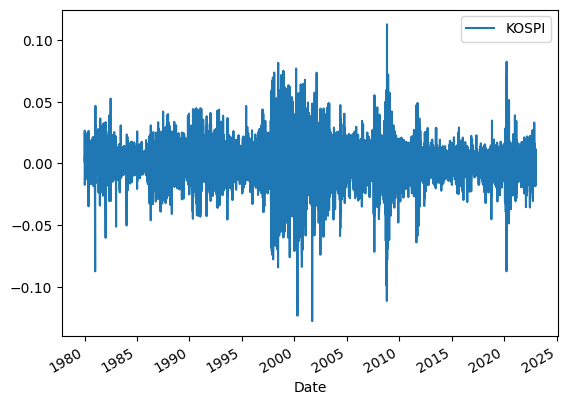

In [5]:
#Read KOSPI
df1 = pd.read_csv('./dat/KOSPI.csv')
df1['Date'] = pd.to_datetime(df1['Date'])
df1.set_index('Date', inplace=True)
df1 = df1.drop('Volume', axis=1)
df1 = df1.drop('Value', axis=1)
df1 = df1.rename(columns={'Close': 'KOSPI'})

df1 = detrend(df1, 'KOSPI')

df1.plot()

In [6]:
df1.head()

,KOSPI
Date,
1980-01-05,0.001499
1980-01-07,0.023486
1980-01-08,0.026468
1980-01-09,0.010300
1980-01-10,0.004690


In [7]:
df1_m = pd.read_csv('./dat/KOSPI.csv')
df1_m['Date'] = pd.to_datetime(df1_m['Date'])
df1_m.set_index('Date', inplace=True)
df1_m = df1_m.drop('Volume', axis=1)
df1_m = df1_m.drop('Value', axis=1)
df1_m = df1_m.rename(columns={'Close': 'KOSPI'})
df1_m.index = pd.to_datetime(df1_m.index)
df1_m = df1_m.resample('M').mean()
df1_m.head()

,KOSPI
Date,
1980-01-31,102.727083
1980-02-29,104.428400
1980-03-31,104.335833
1980-04-30,112.422000
1980-05-31,114.922800


# Autocorrelation

Without detrending

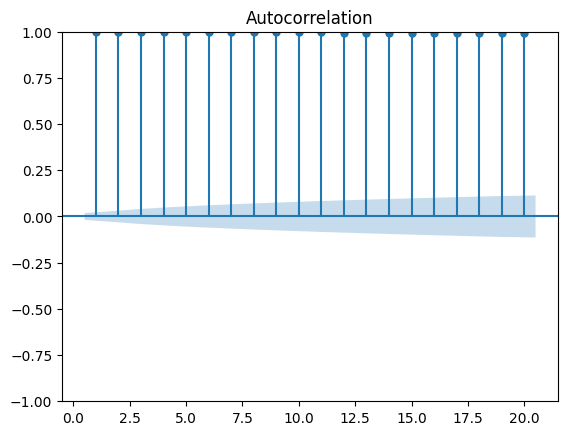

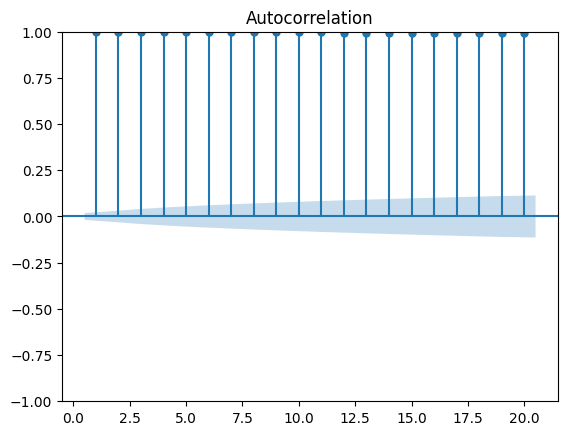

In [8]:
from statsmodels.graphics.tsaplots import plot_acf
df2 = pd.read_csv('./dat/KOSPI.csv')
df2['Date'] = pd.to_datetime(df2['Date'])
df2.set_index('Date', inplace=True)
df2 = df2.drop('Volume', axis=1)
df2 = df2.drop('Value', axis=1)
df2 = df2.rename(columns={'Close': 'KOSPI'})

#df2.head()
plot_acf(df2['KOSPI'], lags=20, use_vlines=True, zero=False)

With detrending

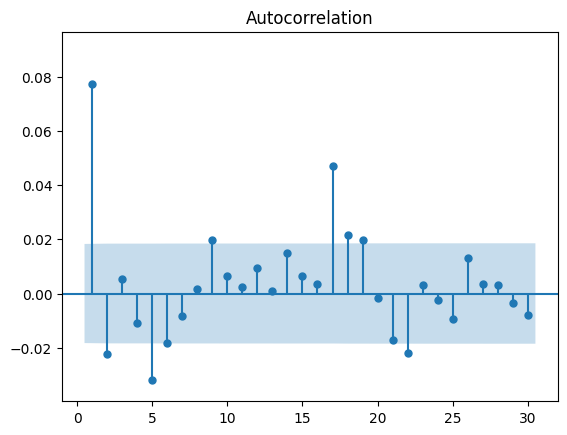

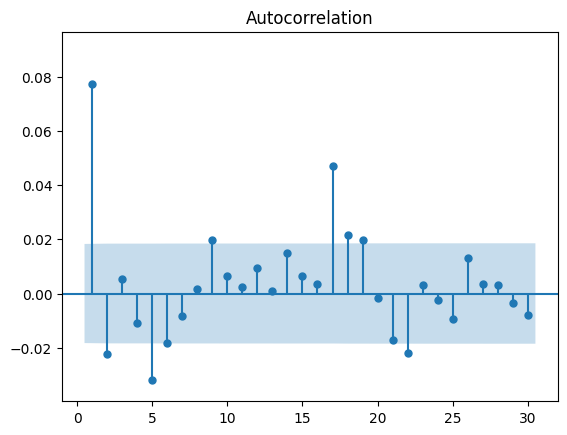

In [9]:
from statsmodels.graphics.tsaplots import plot_acf

plot_acf(df1['KOSPI'], lags=30, use_vlines=True, zero=False, auto_ylims=True)

# DAILY (five datasets)

## KOR5Y

c:\Users\bluebowl\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


,KOR5Y
Date,
1995-05-04,0.0
1995-05-06,0.0
1995-05-08,0.0
1995-05-09,0.0
1995-05-10,0.0


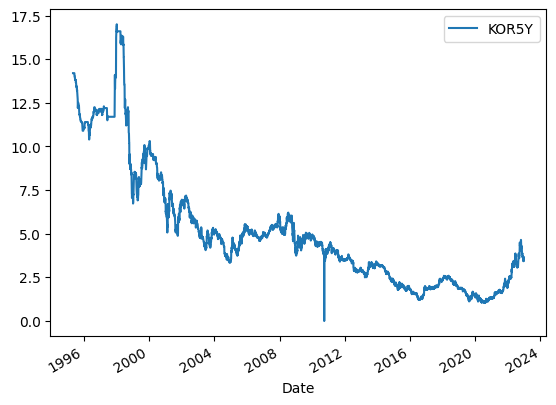

In [10]:
#Read KOR5Y
df2 = pd.read_csv('./dat/KOR5Y.csv')
df2['Date'] = pd.to_datetime(df2['Date'])
df2.set_index('Date', inplace=True)
df2 = df2.rename(columns={'Close': 'KOR5Y'})
df2.plot()
df2 = detrend(df2, 'KOR5Y')
df2.head()

<Axes: xlabel='Date'>

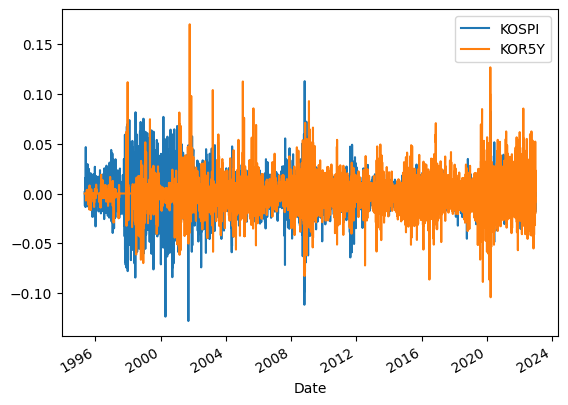

In [11]:
merged = pd.merge(df1, df2, on='Date', how='inner')
merged = dropBad(merged)
merged.head()
merged.plot()

In [12]:
from statsmodels.tsa.stattools import grangercausalitytests
grangercausalitytests(merged[["KOSPI","KOR5Y"]], lags)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=1.1133  , p=0.2914  , df_denom=6901, df_num=1
ssr based chi2 test:   chi2=1.1138  , p=0.2913  , df=1
likelihood ratio test: chi2=1.1137  , p=0.2913  , df=1
parameter F test:         F=1.1133  , p=0.2914  , df_denom=6901, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=0.8660  , p=0.4207  , df_denom=6898, df_num=2
ssr based chi2 test:   chi2=1.7332  , p=0.4204  , df=2
likelihood ratio test: chi2=1.7330  , p=0.4204  , df=2
parameter F test:         F=0.8660  , p=0.4207  , df_denom=6898, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=2.1279  , p=0.0945  , df_denom=6895, df_num=3
ssr based chi2 test:   chi2=6.3902  , p=0.0941  , df=3
likelihood ratio test: chi2=6.3873  , p=0.0942  , df=3
parameter F test:         F=2.1279  , p=0.0945  , df_denom=6895, df_num=3

Granger Causality
number of lags (no zero) 7
ssr based F test:         F=1.3442  , p=0.

{1: ({'ssr_ftest': (1.1133205368266257, 0.29139821286336137, 6901.0, 1),
   'ssr_chi2test': (1.1138045190915842, 0.2912564232845285, 1),
   'lrtest': (1.113714685146988, 0.29127588158836926, 1),
   'params_ftest': (1.1133205368265262, 0.29139821286336137, 6901.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (0.8659933196570379, 0.42067924723268946, 6898.0, 2),
   'ssr_chi2test': (1.733242065987977, 0.42036956707822093, 2),
   'lrtest': (1.7330245065822965, 0.42041529724202265, 2),
   'params_ftest': (0.8659933196571696, 0.42067924723268946, 6898.0, 2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (2.127915989945637, 0.09446491188147811, 6895.0, 3),
   'ssr_chi2test': (6.390228932242835, 0.09409359561489965, 3),
   'lrtest': (6.387272554493393, 0.09421579763696708, 3),
   'params_ftest': (2.127915989946398, 0.09446491188136577, 6895.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.],
          [0., 0., 0., 0., 1., 0., 0.],
          [0

## KOR1Y

c:\Users\bluebowl\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


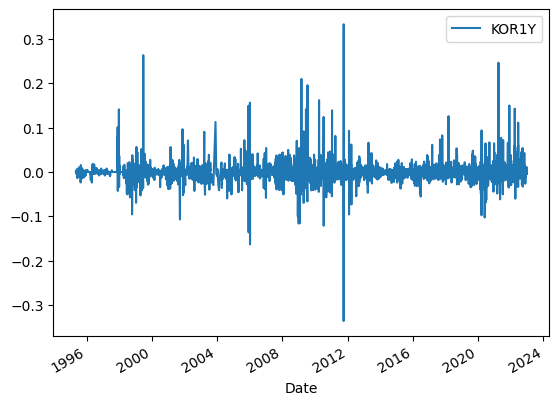

In [13]:
#Read KOR1Y
df2 = pd.read_csv('./dat/KOR1Y.csv')
df2['Date'] = pd.to_datetime(df2['Date'])
df2.set_index('Date', inplace=True)
df2 = df2.rename(columns={'Close': 'KOR1Y'})
df2 = detrend(df2, 'KOR1Y')
df2=dropBad(df2)
df2.plot()

merged = pd.merge(df1, df2, on='Date', how='inner')

In [14]:
from statsmodels.tsa.stattools import grangercausalitytests
grangercausalitytests(merged[['KOSPI','KOR1Y']], lags)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=0.1197  , p=0.7294  , df_denom=6161, df_num=1
ssr based chi2 test:   chi2=0.1197  , p=0.7293  , df=1
likelihood ratio test: chi2=0.1197  , p=0.7293  , df=1
parameter F test:         F=0.1197  , p=0.7294  , df_denom=6161, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=0.0680  , p=0.9343  , df_denom=6158, df_num=2
ssr based chi2 test:   chi2=0.1360  , p=0.9342  , df=2
likelihood ratio test: chi2=0.1360  , p=0.9342  , df=2
parameter F test:         F=0.0680  , p=0.9343  , df_denom=6158, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=0.0692  , p=0.9764  , df_denom=6155, df_num=3
ssr based chi2 test:   chi2=0.2078  , p=0.9763  , df=3
likelihood ratio test: chi2=0.2078  , p=0.9763  , df=3
parameter F test:         F=0.0692  , p=0.9764  , df_denom=6155, df_num=3

Granger Causality
number of lags (no zero) 7
ssr based F test:         F=0.5984  , p=0.

{1: ({'ssr_ftest': (0.11968319011015519, 0.7293901621875495, 6161.0, 1),
   'ssr_chi2test': (0.11974146791738298, 0.7293150577075743, 1),
   'lrtest': (0.11974030488636345, 0.7293163206359652, 1),
   'params_ftest': (0.11968319011368315, 0.7293901621830919, 6161.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (0.06796454081204752, 0.9342943030948686, 6158.0, 2),
   'ssr_chi2test': (0.1360394495045953, 0.934242045702534, 2),
   'lrtest': (0.13603794808295788, 0.9342427470484083, 2),
   'params_ftest': (0.06796454081339817, 0.9342943030935911, 6158.0, 2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (0.06918335658619669, 0.9763591641858881, 6155.0, 3),
   'ssr_chi2test': (0.20778611370470054, 0.9763226723475215, 3),
   'lrtest': (0.20778261045052204, 0.9763232465543372, 3),
   'params_ftest': (0.06918335658625956, 0.9763591641858881, 6155.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.],
          [0., 0., 0., 0., 1., 0., 0.],
       

## S&P 500

<Axes: xlabel='Date'>

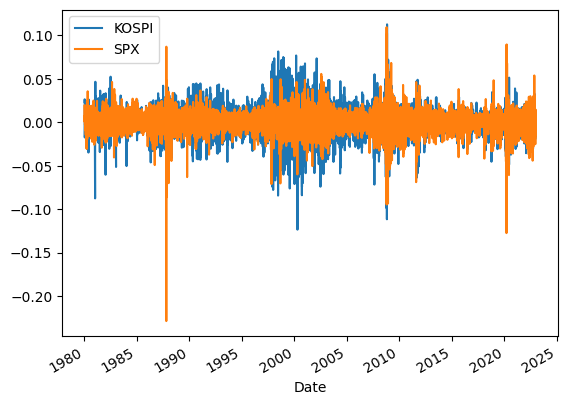

In [15]:
#Read KOR5Y
df2 = pd.read_csv('./dat/SPX.csv')
df2['Date'] = pd.to_datetime(df2['Date'])
df2.set_index('Date', inplace=True)
df2 = df2.rename(columns={'Close': 'SPX'})

df2 = dropBad(detrend(df2, 'SPX'))

merged = pd.merge(df1, df2, on='Date', how='inner')
merged.plot()

In [16]:
from statsmodels.tsa.stattools import grangercausalitytests
grangercausalitytests(merged[['KOSPI','SPX']], lags)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=625.0589, p=0.0000  , df_denom=10257, df_num=1
ssr based chi2 test:   chi2=625.2418, p=0.0000  , df=1
likelihood ratio test: chi2=606.9310, p=0.0000  , df=1
parameter F test:         F=625.0589, p=0.0000  , df_denom=10257, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=317.2898, p=0.0000  , df_denom=10254, df_num=2
ssr based chi2 test:   chi2=634.8890, p=0.0000  , df=2
likelihood ratio test: chi2=616.0182, p=0.0000  , df=2
parameter F test:         F=317.2898, p=0.0000  , df_denom=10254, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=217.3564, p=0.0000  , df_denom=10251, df_num=3
ssr based chi2 test:   chi2=652.5146, p=0.0000  , df=3
likelihood ratio test: chi2=632.6014, p=0.0000  , df=3
parameter F test:         F=217.3564, p=0.0000  , df_denom=10251, df_num=3

Granger Causality
number of lags (no zero) 7
ssr based F test:         F=94.4084 

{1: ({'ssr_ftest': (625.0589332658824, 5.771317484214841e-134, 10257.0, 1),
   'ssr_chi2test': (625.2417524917572, 5.416300452198822e-138, 1),
   'lrtest': (606.9309606284223, 5.2032444813845505e-134, 1),
   'params_ftest': (625.0589332658842, 5.77131748421156e-134, 10257.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (317.2897635340233, 1.9885349865792755e-134, 10254.0, 2),
   'ssr_chi2test': (634.8889573035976, 1.3665156533382377e-138, 2),
   'lrtest': (616.0182416464086, 1.7113484688036526e-134, 2),
   'params_ftest': (317.28976353402174,
    1.9885349865828925e-134,
    10254.0,
    2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (217.35643155643493, 1.053148180799567e-136, 10251.0, 3),
   'ssr_chi2test': (652.5145668439886, 4.151082296871303e-141, 3),
   'lrtest': (632.6013658379379, 8.62082464524662e-137, 3),
   'params_ftest': (217.3564315564365, 1.0531481807976514e-136, 10251.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.

## Gold

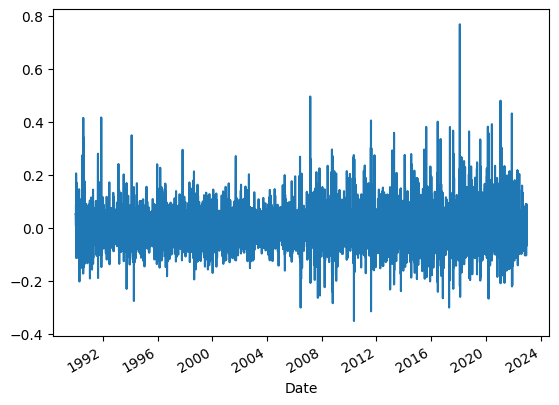

In [17]:
#Read KOR5Y
df2 = pd.read_csv('./dat/GOLDFUTURES.csv')
df2['Date'] = pd.to_datetime(df2['Date'])
df2.set_index('Date', inplace=True)
df2 = df2.rename(columns={'Close': 'GOLD'})

df2 = dropBad(detrend(df2, 'GOLD'))
df2['GOLD'].plot()

merged = pd.merge(df1, df2, on='Date', how='inner')

In [18]:
from statsmodels.tsa.stattools import grangercausalitytests
grangercausalitytests(merged[['KOSPI','GOLD']], lags)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=400.0120, p=0.0000  , df_denom=7882, df_num=1
ssr based chi2 test:   chi2=400.1643, p=0.0000  , df=1
likelihood ratio test: chi2=390.3411, p=0.0000  , df=1
parameter F test:         F=400.0120, p=0.0000  , df_denom=7882, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=208.3623, p=0.0000  , df_denom=7879, df_num=2
ssr based chi2 test:   chi2=416.9890, p=0.0000  , df=2
likelihood ratio test: chi2=406.3357, p=0.0000  , df=2
parameter F test:         F=208.3623, p=0.0000  , df_denom=7879, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=141.5499, p=0.0000  , df_denom=7876, df_num=3
ssr based chi2 test:   chi2=425.0270, p=0.0000  , df=3
likelihood ratio test: chi2=413.9648, p=0.0000  , df=3
parameter F test:         F=141.5499, p=0.0000  , df_denom=7876, df_num=3

Granger Causality
number of lags (no zero) 7
ssr based F test:         F=62.1525 , p=0.

{1: ({'ssr_ftest': (400.01203932567483, 7.608851250154685e-87, 7882.0, 1),
   'ssr_chi2test': (400.1642895309497, 5.071902605164301e-89, 1),
   'lrtest': (390.34109028306557, 6.976242617067112e-87, 1),
   'params_ftest': (400.0120393256723, 7.608851250161821e-87, 7882.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (208.36228028401857, 6.626607347012315e-89, 7879.0, 2),
   'ssr_chi2test': (416.98901326544035, 2.831302433788135e-91, 2),
   'lrtest': (406.3356570143951, 5.8254996306322316e-89, 2),
   'params_ftest': (208.3622802840176, 6.62660734701853e-89, 7879.0, 2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (141.54985816014224, 2.4780964865882096e-89, 7876.0, 3),
   'ssr_chi2test': (425.0269928427125, 8.389338431414117e-92, 3),
   'lrtest': (413.96481087662687, 2.090020643524163e-89, 3),
   'params_ftest': (141.54985816014172, 2.4780964865893363e-89, 7876.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.],
          [0., 0., 0., 0

## VIX

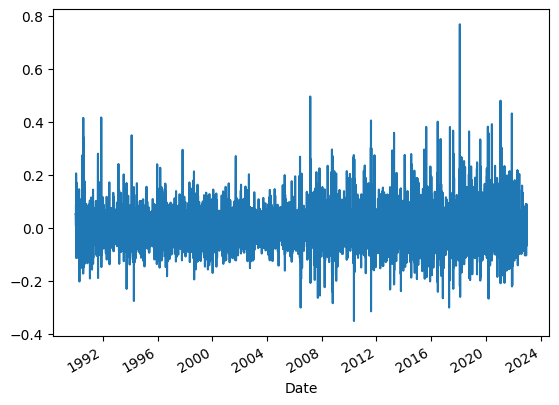

In [19]:
#Read VIX
df2 = pd.read_csv('./dat/VIX.csv')
df2['Date'] = pd.to_datetime(df2['Date'])
df2.set_index('Date', inplace=True)
df2 = df2.rename(columns={'Close': 'VIX'})

df2 = dropBad(detrend(df2, 'VIX'))
df2['VIX'].plot()

merged = pd.merge(df1, df2, on='Date', how='inner')

In [20]:
from statsmodels.tsa.stattools import grangercausalitytests
grangercausalitytests(merged[['KOSPI','VIX']], lags)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=400.0120, p=0.0000  , df_denom=7882, df_num=1
ssr based chi2 test:   chi2=400.1643, p=0.0000  , df=1
likelihood ratio test: chi2=390.3411, p=0.0000  , df=1
parameter F test:         F=400.0120, p=0.0000  , df_denom=7882, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=208.3623, p=0.0000  , df_denom=7879, df_num=2
ssr based chi2 test:   chi2=416.9890, p=0.0000  , df=2
likelihood ratio test: chi2=406.3357, p=0.0000  , df=2
parameter F test:         F=208.3623, p=0.0000  , df_denom=7879, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=141.5499, p=0.0000  , df_denom=7876, df_num=3
ssr based chi2 test:   chi2=425.0270, p=0.0000  , df=3
likelihood ratio test: chi2=413.9648, p=0.0000  , df=3
parameter F test:         F=141.5499, p=0.0000  , df_denom=7876, df_num=3

Granger Causality
number of lags (no zero) 7
ssr based F test:         F=62.1525 , p=0.

{1: ({'ssr_ftest': (400.01203932567483, 7.608851250154685e-87, 7882.0, 1),
   'ssr_chi2test': (400.1642895309497, 5.071902605164301e-89, 1),
   'lrtest': (390.34109028306557, 6.976242617067112e-87, 1),
   'params_ftest': (400.0120393256723, 7.608851250161821e-87, 7882.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (208.36228028401857, 6.626607347012315e-89, 7879.0, 2),
   'ssr_chi2test': (416.98901326544035, 2.831302433788135e-91, 2),
   'lrtest': (406.3356570143951, 5.8254996306322316e-89, 2),
   'params_ftest': (208.3622802840176, 6.62660734701853e-89, 7879.0, 2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (141.54985816014224, 2.4780964865882096e-89, 7876.0, 3),
   'ssr_chi2test': (425.0269928427125, 8.389338431414117e-92, 3),
   'lrtest': (413.96481087662687, 2.090020643524163e-89, 3),
   'params_ftest': (141.54985816014172, 2.4780964865893363e-89, 7876.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.],
          [0., 0., 0., 0

## USDKRW

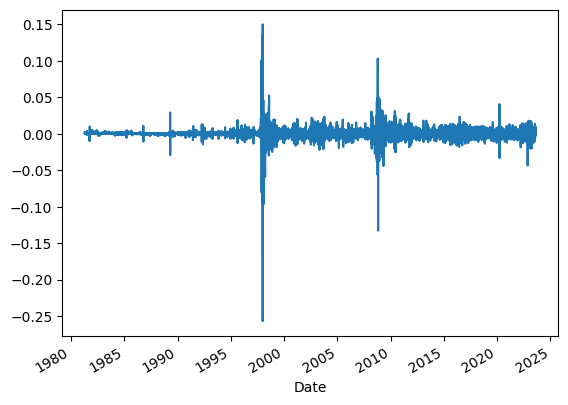

In [21]:
#Read USDKRW
df2 = pd.read_csv('./dat/USDKRW.csv')
df2['Date'] = pd.to_datetime(df2['Date'])
df2.set_index('Date', inplace=True)
df2 = df2.rename(columns={'Close': 'USDKRW'})
df2.head()

df2 = dropBad(detrend(df2, 'USDKRW'))
df2['USDKRW'].plot()

merged = pd.merge(df1, df2, on='Date', how='inner')

In [22]:
from statsmodels.tsa.stattools import grangercausalitytests
grangercausalitytests(merged[['KOSPI','USDKRW']], lags)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=38.9665 , p=0.0000  , df_denom=10118, df_num=1
ssr based chi2 test:   chi2=38.9780 , p=0.0000  , df=1
likelihood ratio test: chi2=38.9032 , p=0.0000  , df=1
parameter F test:         F=38.9665 , p=0.0000  , df_denom=10118, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=23.6118 , p=0.0000  , df_denom=10115, df_num=2
ssr based chi2 test:   chi2=47.2469 , p=0.0000  , df=2
likelihood ratio test: chi2=47.1370 , p=0.0000  , df=2
parameter F test:         F=23.6118 , p=0.0000  , df_denom=10115, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=19.8530 , p=0.0000  , df_denom=10112, df_num=3
ssr based chi2 test:   chi2=59.6003 , p=0.0000  , df=3
likelihood ratio test: chi2=59.4255 , p=0.0000  , df=3
parameter F test:         F=19.8530 , p=0.0000  , df_denom=10112, df_num=3

Granger Causality
number of lags (no zero) 7
ssr based F test:         F=10.3086 

{1: ({'ssr_ftest': (38.96648320719243, 4.4843587767484364e-10, 10118.0, 1),
   'ssr_chi2test': (38.97803681952902, 4.286004328311252e-10, 1),
   'lrtest': (38.9031727812544, 4.453561793964367e-10, 1),
   'params_ftest': (38.966483207195864, 4.4843587767398973e-10, 10118.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (23.611783385973887, 5.880251078444519e-11, 10115.0, 2),
   'ssr_chi2test': (47.24691010698087, 5.501280973780044e-11, 2),
   'lrtest': (47.136962135948124, 5.812175578827012e-11, 2),
   'params_ftest': (23.61178338597285, 5.880251078450953e-11, 10115.0, 2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (19.85303683123904, 7.945631947416077e-13, 10112.0, 3),
   'ssr_chi2test': (59.600340099478196, 7.155280771052682e-13, 3),
   'lrtest': (59.42550495309115, 7.797836955315513e-13, 3),
   'params_ftest': (19.85303683123877, 7.945631947420086e-13, 10112.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.],
          [0., 0., 0.,

## Volumne per investor type

<Axes: xlabel='Date'>

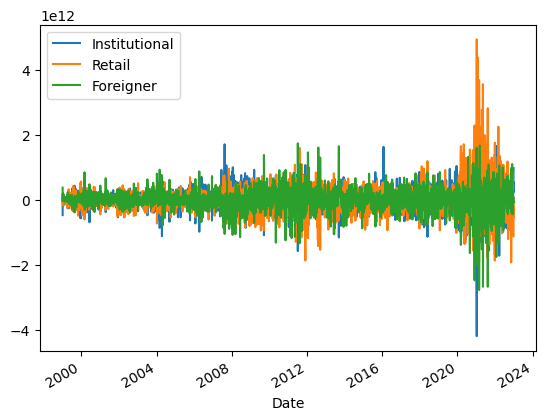

In [23]:
#Read VOL
df_vol = pd.read_csv('./dat/KOSPIVOL.csv')
df_vol['Date'] = pd.to_datetime(df_vol['Date'])
df_vol.set_index('Date', inplace=True)
df_vol.plot()

### Institutions

c:\Users\bluebowl\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


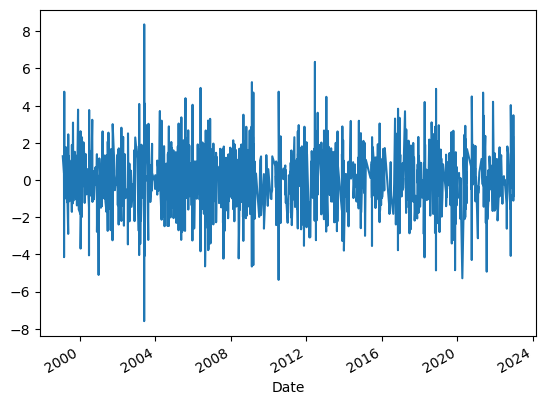

In [24]:
df2 = df_vol
df2.drop('Retail', axis=1)
df2.drop('Foreigner', axis=1)

df2 = dropBad(detrend(df2, 'Institutional'))
df2['Institutional'].plot()

merged = pd.merge(df1, df2, on='Date', how='inner')

In [25]:
from statsmodels.tsa.stattools import grangercausalitytests
grangercausalitytests(merged[['KOSPI','Institutional']], lags)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=2.8238  , p=0.0931  , df_denom=1649, df_num=1
ssr based chi2 test:   chi2=2.8289  , p=0.0926  , df=1
likelihood ratio test: chi2=2.8265  , p=0.0927  , df=1
parameter F test:         F=2.8238  , p=0.0931  , df_denom=1649, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=0.9702  , p=0.3792  , df_denom=1646, df_num=2
ssr based chi2 test:   chi2=1.9462  , p=0.3779  , df=2
likelihood ratio test: chi2=1.9451  , p=0.3781  , df=2
parameter F test:         F=0.9702  , p=0.3792  , df_denom=1646, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=1.0368  , p=0.3752  , df_denom=1643, df_num=3
ssr based chi2 test:   chi2=3.1237  , p=0.3729  , df=3
likelihood ratio test: chi2=3.1208  , p=0.3734  , df=3
parameter F test:         F=1.0368  , p=0.3752  , df_denom=1643, df_num=3

Granger Causality
number of lags (no zero) 7
ssr based F test:         F=0.8117  , p=0.

{1: ({'ssr_ftest': (2.82375591501679, 0.09306823461085471, 1649.0, 1),
   'ssr_chi2test': (2.8288931301441704, 0.09258214901643266, 1),
   'lrtest': (2.8264737862518814, 0.09272174363253068, 1),
   'params_ftest': (2.823755915016587, 0.0930682346108705, 1649.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (0.9701675492023876, 0.37923615316930614, 1646.0, 2),
   'ssr_chi2test': (1.9462291904412417, 0.3779041846633242, 2),
   'lrtest': (1.9450829657489521, 0.37812082829185373, 2),
   'params_ftest': (0.9701675492024869, 0.3792361531692715, 1646.0, 2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (1.0368217386320058, 0.3752017198279218, 1643.0, 3),
   'ssr_chi2test': (3.123717350108599, 0.37294092477026897, 3),
   'lrtest': (3.1207642251411016, 0.3733778821969587, 3),
   'params_ftest': (1.0368217386318437, 0.37520171982803097, 1643.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.],
          [0., 0., 0., 0., 1., 0., 0.],
          [0.,

### Retail

c:\Users\bluebowl\AppData\Local\Programs\Python\Python310\lib\site-packages\pandas\core\arraylike.py:402: RuntimeWarning: invalid value encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


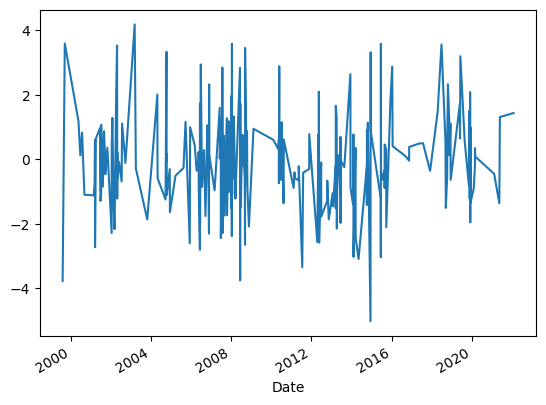

In [26]:
df2 = df_vol
df2.drop('Institutional', axis=1)
df2.drop('Foreigner', axis=1)

df2 = dropBad(detrend(df2, 'Retail'))

df2['Retail'].plot()

merged = pd.merge(df1, df2, on='Date', how='inner')

In [27]:
from statsmodels.tsa.stattools import grangercausalitytests
grangercausalitytests(merged[['KOSPI','Retail']], lags)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=2.6057  , p=0.1077  , df_denom=263, df_num=1
ssr based chi2 test:   chi2=2.6354  , p=0.1045  , df=1
likelihood ratio test: chi2=2.6225  , p=0.1054  , df=1
parameter F test:         F=2.6057  , p=0.1077  , df_denom=263, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=1.2519  , p=0.2877  , df_denom=260, df_num=2
ssr based chi2 test:   chi2=2.5520  , p=0.2792  , df=2
likelihood ratio test: chi2=2.5398  , p=0.2809  , df=2
parameter F test:         F=1.2519  , p=0.2877  , df_denom=260, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=1.0377  , p=0.3764  , df_denom=257, df_num=3
ssr based chi2 test:   chi2=3.1980  , p=0.3621  , df=3
likelihood ratio test: chi2=3.1788  , p=0.3649  , df=3
parameter F test:         F=1.0377  , p=0.3764  , df_denom=257, df_num=3

Granger Causality
number of lags (no zero) 7
ssr based F test:         F=1.1116  , p=0.3563  

{1: ({'ssr_ftest': (2.6057211748021176, 0.1076778036811141, 263.0, 1),
   'ssr_chi2test': (2.6354442300279977, 0.10450282788814927, 1),
   'lrtest': (2.6224742522390443, 0.1053600390081529, 1),
   'params_ftest': (2.6057211748020843, 0.10767780368111728, 263.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (1.251918674548464, 0.2876735295834283, 260.0, 2),
   'ssr_chi2test': (2.551988067348792, 0.27915334243687573, 2),
   'lrtest': (2.539778386244052, 0.28086274157773744, 2),
   'params_ftest': (1.2519186745484934, 0.28767352958341924, 260.0, 2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (1.0377388662549714, 0.37638573994467, 257.0, 3),
   'ssr_chi2test': (3.1980123816106505, 0.3620915081183146, 3),
   'lrtest': (3.1787975463898874, 0.3648710971282382, 3),
   'params_ftest': (1.037738866254949, 0.3763857399446783, 257.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.],
          [0., 0., 0., 0., 1., 0., 0.],
          [0., 0., 0., 0

### Foreigner

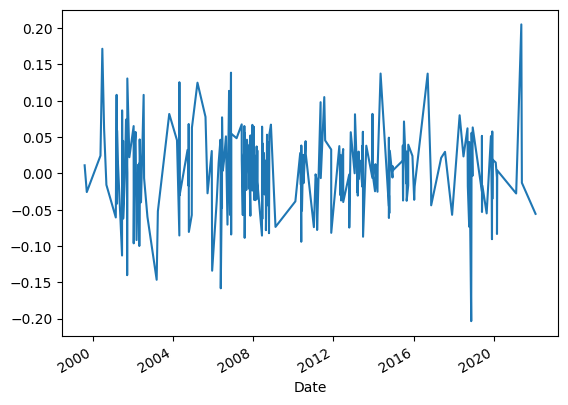

In [28]:
df2 = df_vol
df2.drop('Retail', axis=1)
df2.drop('Foreigner', axis=1)

df2 = dropBad(detrend(df2, 'Institutional'))
df2['Institutional'].plot()

merged = pd.merge(df1, df2, on='Date', how='inner')

In [29]:
from statsmodels.tsa.stattools import grangercausalitytests
grangercausalitytests(merged[['KOSPI','Institutional']], lags)


Granger Causality
number of lags (no zero) 1
ssr based F test:         F=2.9601  , p=0.0865  , df_denom=263, df_num=1
ssr based chi2 test:   chi2=2.9939  , p=0.0836  , df=1
likelihood ratio test: chi2=2.9771  , p=0.0844  , df=1
parameter F test:         F=2.9601  , p=0.0865  , df_denom=263, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=1.3692  , p=0.2561  , df_denom=260, df_num=2
ssr based chi2 test:   chi2=2.7912  , p=0.2477  , df=2
likelihood ratio test: chi2=2.7766  , p=0.2495  , df=2
parameter F test:         F=1.3692  , p=0.2561  , df_denom=260, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=0.8351  , p=0.4756  , df_denom=257, df_num=3
ssr based chi2 test:   chi2=2.5736  , p=0.4621  , df=3
likelihood ratio test: chi2=2.5611  , p=0.4644  , df=3
parameter F test:         F=0.8351  , p=0.4756  , df_denom=257, df_num=3

Granger Causality
number of lags (no zero) 7
ssr based F test:         F=1.1557  , p=0.3291  

{1: ({'ssr_ftest': (2.9600850508756387, 0.08651964807324446, 263.0, 1),
   'ssr_chi2test': (2.993850279592851, 0.08358122085177157, 1),
   'lrtest': (2.977127632479551, 0.0844490199715429, 1),
   'params_ftest': (2.9600850508756262, 0.08651964807324446, 263.0, 1.0)},
   array([[0., 1., 0.]])]),
 2: ({'ssr_ftest': (1.3692496835104322, 0.25612517748279623, 260.0, 2),
   'ssr_chi2test': (2.7911628163866506, 0.24768898608937195, 2),
   'lrtest': (2.7765659966112253, 0.2495033347107802, 2),
   'params_ftest': (1.3692496835104382, 0.25612517748278774, 260.0, 2.0)},
   array([[0., 0., 1., 0., 0.],
          [0., 0., 0., 1., 0.]])]),
 3: ({'ssr_ftest': (0.8351051530231195, 0.47564870737841414, 257.0, 3),
   'ssr_chi2test': (2.573553623324166, 0.4621448130982625, 3),
   'lrtest': (2.5610906549086394, 0.4643517243694528, 3),
   'params_ftest': (0.8351051530231094, 0.47564870737842446, 257.0, 3.0)},
   array([[0., 0., 0., 1., 0., 0., 0.],
          [0., 0., 0., 0., 1., 0., 0.],
          [0., 0.,